# Training the downscaler

AIFS-ENS forecasts 2 m temperature on a 0.25° grid, about 25 km. The downscaler in
[tutorial.ipynb](tutorial_inference.ipynb) adds the detail that grid cannot hold: it learned it from ERA5, which
has the same 0.25° grid, paired with CERRA, a 5.5 km reanalysis of Europe. This notebook trains a small
version of it from scratch, so every step can be seen:

- **a. Set up**: the settings of the published model, and a short training budget.
- **b. Build the training pairs**: CERRA from the Hub, ERA5 from Earthmover interpolated onto the CERRA grid.
- **c. What the model has to learn**: the difference between the two, which follows the terrain.
- **d. The model**: its inputs, the correction it predicts, and the noise that makes it an ensemble.
- **e. Train**: a few hundred steps on 2019, scored on 2020 against plain interpolation.
- **f. Check and save**: maps of the result, scores by elevation, and a checkpoint that
  [tutorial.ipynb](tutorial_inference.ipynb) can load.

The published model is trained the same way by `scripts/build_pairs.py` and `scripts/train_downscaler.py`,
on six years (2014 to 2019) for 20 epochs. One year and a few hundred steps already beat interpolation
clearly, but stay behind it.

## a. Set up

Install the repository as for the forecast tutorial (`uv sync`). ERA5 is read from Earthmover's public
copy, which needs a free account: `uv run arraylake auth login`, or `ARRAYLAKE_TOKEN` in the environment.
CERRA is read from the Hub and needs nothing.

The model settings come from `config.yaml`, the file the training script reads, so this notebook trains
the same architecture as the published model. Only the amount of data and of training is cut down.
Training uses a GPU, or Apple silicon through MPS, when there is one; on a CPU, section e is slow.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from downscale import downscaler as dsc
from downscale.config import load_config
from downscale.constants import COARSE_CROP_MARGIN_DEG, COAST_CHANNEL, ZERO_C, elevation_edges
from downscale.diagnostics import distance_to_coast_km, grid_spacing_km, land_mask, maritime_influence
from downscale.fetch import get_target, load_with_retries
from downscale.plots import maps
from downscale.sources import ERA5

from scripts.build_pairs import CoarseOnTargetGrid
from scripts.train_downscaler import validate

CERRA_REPO = "EmmaScharfmann/cerra-france-t2m-2016-2020"   # CERRA over France, 2014 to 2020, every 6 h
TRAIN = ("2019-01-01", "2019-12-31 18:00")                  # one year to learn from
VALIDATION_DAYS = pd.date_range("2020-01-01", "2020-12-31", freq="10D")   # every 10th day of 2020

CFG = load_config("config.yaml").training   # the published model's settings
EPOCHS, STEPS_PER_EPOCH = 4, 100            # the published model: 20 epochs over six years
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
OUT = Path("runs/tutorial")
torch.manual_seed(CFG.seed)
rng = np.random.default_rng(CFG.seed)
print(f"{CFG.loss} loss, {CFG.members} members per input, batch of {CFG.batch_size}, on {DEVICE}")

crps loss, 4 members per input, batch of 8, on mps


## b. Build the training pairs

A pair is the same moment seen twice: by ERA5, on its 0.25° grid, and by CERRA, at 5.5 km. CERRA is
driven by ERA5 at its boundaries, so the two agree on the weather and differ in the detail, which is what
the model learns.

CERRA comes from the Hub, with its orography and land-sea mask. Its grid is a Lambert projection, so
latitude and longitude are two-dimensional.

In [2]:
cerra, cerra_static = get_target(TRAIN[0], "2020-12-31 18:00", repo=CERRA_REPO)
times = pd.DatetimeIndex(cerra.time.values)
wanted = ((times >= TRAIN[0]) & (times <= TRAIN[1])) | times.normalize().isin(VALIDATION_DAYS)
cerra = load_with_retries(cerra.isel(time=np.flatnonzero(wanted)))
times = pd.DatetimeIndex(cerra.time.values)
lat, lon = cerra.lat.values, cerra.lon.values
fine = cerra.t2m.values.astype("f4")                                   # (time, y, x) [K]
print(f"CERRA: {len(times)} times on a {lat.shape[0]} x {lat.shape[1]} grid, "
      f"{grid_spacing_km(lat, lon):.2f} km apart")

CERRA: 1608 times on a 228 x 238 grid, 5.48 km apart


ERA5 is read from Earthmover. Its `single/temporal` copy stores long time series over small tiles, so a
year over France is a few small reads; the `single/spatial` copy, one global field per chunk, would
download the whole globe at every time. Each field is then interpolated bilinearly onto the CERRA grid:
this interpolated field is both the model's main input and the baseline it has to beat.

In [3]:
margin = COARSE_CROP_MARGIN_DEG + 0.5
era5 = ERA5(group="single/temporal",
            box=(lat.min() - margin, lat.max() + margin, lon.min() - margin, lon.max() + margin))
on_cerra_grid = CoarseOnTargetGrid(era5, lat, lon, "t2m", batch=400)
started = time.time()
coarse = on_cerra_grid.field(times)                                     # (time, y, x) [K]
print(f"ERA5: {coarse.shape[0]} times read and interpolated in {time.time() - started:.0f} s")

static = {
    "cerra_orography": cerra_static.orography.values.astype("f4"),
    "era5_orography": on_cerra_grid.surface_height(era5.surface_geopotential()),
    "land_sea_mask": cerra_static.land_sea_mask.values.astype("f4"),
    "lat": lat.astype("f4"),
    "lon": lon.astype("f4"),
}
land = land_mask(static)
static[COAST_CHANNEL] = maritime_influence(distance_to_coast_km(land, grid_spacing_km(lat, lon)),
                                           CFG.coast_decay_km)
train = np.flatnonzero(times <= pd.Timestamp(TRAIN[1]))
val = np.flatnonzero(times > pd.Timestamp(TRAIN[1]))
print(f"{len(train)} training and {len(val)} validation times; {land.mean():.0%} of the grid is land")

ERA5: 1608 times read and interpolated in 71 s
1460 training and 148 validation times; 66% of the grid is land


## c. What the model has to learn

On a summer afternoon, ERA5 already has the large-scale pattern; CERRA adds the Alps, the Pyrenees, the
Massif Central and the valleys between them. Their difference, on the right, is what the model predicts.
The sea is hidden: CERRA's sea temperature comes from a different process, so the model is trained over
land only.

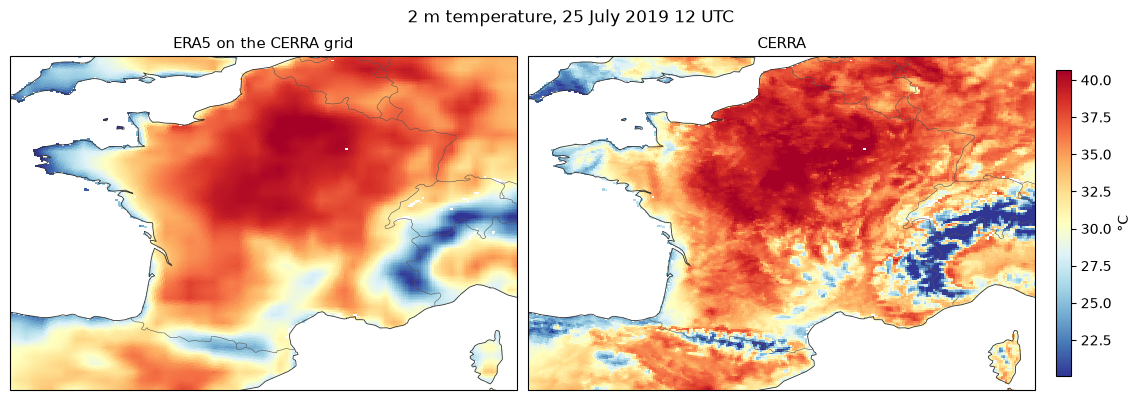

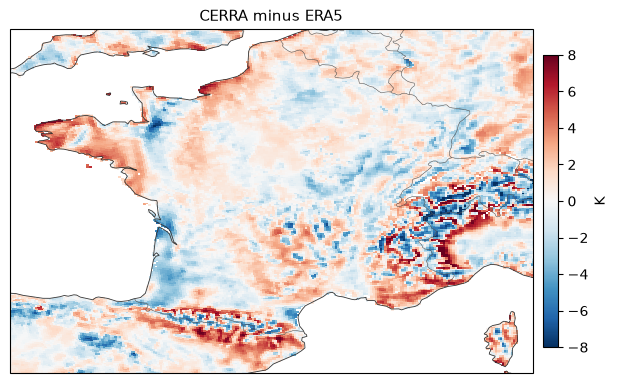

In [4]:
on_land = lambda field: np.where(land, field, np.nan)
k = int(np.abs(times - pd.Timestamp("2019-07-25 12:00")).argmin())
fig = maps([
    ("ERA5 on the CERRA grid", lon, lat, on_land(coarse[k] - ZERO_C)),
    ("CERRA", lon, lat, on_land(fine[k] - ZERO_C)),
], title=f"2 m temperature, {times[k]:%d %B %Y %H} UTC")
fig = maps([("CERRA minus ERA5", lon, lat, on_land(fine[k] - coarse[k]))], cmap="RdBu_r", vmin=-8, vmax=8,
           label="K")

Most of that difference follows the height of the ground. Averaged over the training year, each point's
difference falls with how far CERRA's terrain rises above ERA5's, by several kelvin per kilometre: the
order of the 6.5 K per km at which temperature drops with height in the atmosphere. The scatter around
the line is the rest: coasts, valleys, time of day and weather, which the model has to work out from its
other inputs.

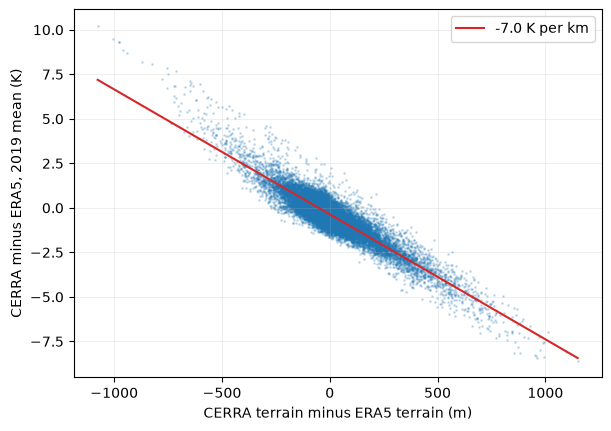

In [5]:
height_diff = static["cerra_orography"] - static["era5_orography"]
mean_diff = (fine[train] - coarse[train]).mean(0)
slope, intercept = np.polyfit(height_diff[land], mean_diff[land], 1)
fig, axis = plt.subplots(figsize=(6, 4.2), layout="constrained")
axis.scatter(height_diff[land], mean_diff[land], s=1, alpha=0.2, color="tab:blue")
span = np.array([height_diff[land].min(), height_diff[land].max()])
axis.plot(span, intercept + slope * span, color="tab:red", label=f"{1000 * slope:.1f} K per km")
axis.set_xlabel("CERRA terrain minus ERA5 terrain (m)")
axis.set_ylabel("CERRA minus ERA5, 2019 mean (K)")
axis.legend()
axis.grid(alpha=0.3)

## d. The model

The network is a small U-Net. For each time it sees the interpolated ERA5 field and fixed maps of the
place, all on the CERRA grid: the terrain, how much higher it is than ERA5's, the land-sea mask, latitude,
longitude, the distance to the sea, and the time of day and of year. It predicts the **correction** to add
to the interpolated field, not the temperature itself, so it only has to learn the detail.

Two extra input channels hold random noise, so every pass gives a different, plausible correction: one
input becomes an ensemble. The **CRPS** loss trains that ensemble as a whole. It rewards members that
are close to CERRA and penalises members that are all alike, so the ensemble learns how uncertain the
detail is as well as what it looks like.

Every input is standardised with statistics from the training year over land; the checkpoint keeps them,
so a forecast is normalised the same way later.

In [6]:
moments = lambda values: {"mean": float(np.mean(values)), "std": float(np.std(values))}
stats = {
    "era5_t2m": moments(coarse[train][:, land]),
    "residual": moments((fine[train] - coarse[train])[:, land]),
    "cerra_orography": moments(static["cerra_orography"]),
    "orography_diff": moments(height_diff),
    **{key: moments(static[key]) for key in ("lat", "lon", COAST_CHANNEL)},
}
static_norm = dsc.static_stack(static, stats, CFG.coast_distance)

model_cfg = dsc.Config(
    loss=CFG.loss, base=CFG.base_channels, depth=CFG.depth, noise_channels=CFG.noise_channels,
    upsample=CFG.upsample, noise_fine_fraction=CFG.noise_fine_fraction,
    noise_coarse_factor=CFG.noise_coarse_factor, coast_distance=CFG.coast_distance,
)
net = dsc.DownscalerNet(model_cfg).to(DEVICE)
print(f"inputs: {', '.join(model_cfg.channels)}, and {model_cfg.noise_channels} noise channels")
print(f"{sum(p.numel() for p in net.parameters()) / 1e6:.2f} M parameters")

inputs: era5_t2m, cerra_orography, orography_diff, land_sea_mask, lat, lon, coast_distance, hour_sin, hour_cos, doy_sin, doy_cos, and 2 noise channels
2.15 M parameters


## e. Train

Each step draws a batch of training times, gives each `CFG.members` noise draws, and scores the resulting
ensembles against CERRA over land. After each epoch, the model is scored on the 2020 validation days
against plain interpolation, and the best checkpoint so far is kept.

In [7]:
optimiser = torch.optim.AdamW(net.parameters(), lr=CFG.learning_rate, weight_decay=CFG.weight_decay)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimiser, max_lr=CFG.learning_rate,
                                                total_steps=EPOCHS * STEPS_PER_EPOCH)
loss_mask = torch.from_numpy(land).to(DEVICE)
OUT.mkdir(parents=True, exist_ok=True)
history, best = [], None
for epoch in range(1, EPOCHS + 1):
    started, losses = time.time(), []
    for step in range(STEPS_PER_EPOCH):
        idx = np.sort(rng.choice(train, CFG.batch_size, replace=False))
        x = torch.from_numpy(dsc.make_inputs(coarse[idx], times[idx].to_numpy(), static_norm, stats)).to(DEVICE)
        target = torch.from_numpy(dsc.residual_norm(coarse[idx], fine[idx], stats)).to(DEVICE)
        loss = dsc.fair_crps(net(x, CFG.members), target, loss_mask)
        optimiser.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        optimiser.step()
        scheduler.step()
        losses.append(loss.item())
    model_scores, interpolation = validate(net, coarse[val], fine[val], times[val].to_numpy(), static_norm, stats,
                                           CFG.eval_members, DEVICE, groups={"land": land})
    scores = model_scores["land"]
    history.append({"epoch": epoch, "loss": np.mean(losses), "rmse": scores["rmse"], "crps": scores["crps"]})
    print(f"epoch {epoch}: loss {np.mean(losses):.3f}, validation RMSE {scores['rmse']:.2f} K "
          f"(interpolation {interpolation['land']['rmse']:.2f}), CRPS {scores['crps']:.2f} K "
          f"(interpolation {interpolation['land']['crps']:.2f}) [{time.time() - started:.0f} s]")
    if best is None or scores["crps"] < best:
        best = scores["crps"]
        dsc.Downscaler(net, stats, static, DEVICE).save(OUT / "model.pt", extra={"epoch": epoch, "land_only": True})

epoch 1: loss 0.571, validation RMSE 1.30 K (interpolation 1.60), CRPS 0.65 K (interpolation 1.12) [77 s]
epoch 2: loss 0.400, validation RMSE 1.25 K (interpolation 1.60), CRPS 0.63 K (interpolation 1.12) [75 s]
epoch 3: loss 0.384, validation RMSE 1.22 K (interpolation 1.60), CRPS 0.62 K (interpolation 1.12) [75 s]
epoch 4: loss 0.382, validation RMSE 1.22 K (interpolation 1.60), CRPS 0.61 K (interpolation 1.12) [79 s]


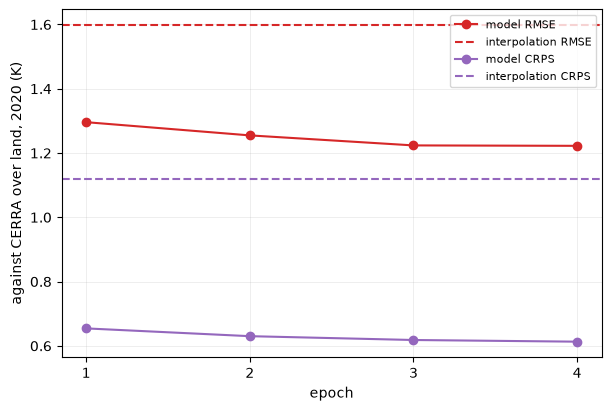

In [8]:
history = pd.DataFrame(history).set_index("epoch")
fig, axis = plt.subplots(figsize=(6, 4), layout="constrained")
for metric, colour in (("rmse", "tab:red"), ("crps", "tab:purple")):
    axis.plot(history.index, history[metric], marker="o", color=colour, label=f"model {metric.upper()}")
    axis.axhline(interpolation["land"][metric], color=colour, ls="--", label=f"interpolation {metric.upper()}")
axis.set_xlabel("epoch")
axis.set_ylabel("against CERRA over land, 2020 (K)")
axis.set_xticks(history.index)
axis.legend(fontsize=8)
axis.grid(alpha=0.3)

## f. Check and save

The best checkpoint loads like the published model. On a summer afternoon of the validation year, the
members add the terrain to ERA5 and differ from each other in the detail; their mean is smoother than
any one of them, because the members disagree on the small scales.

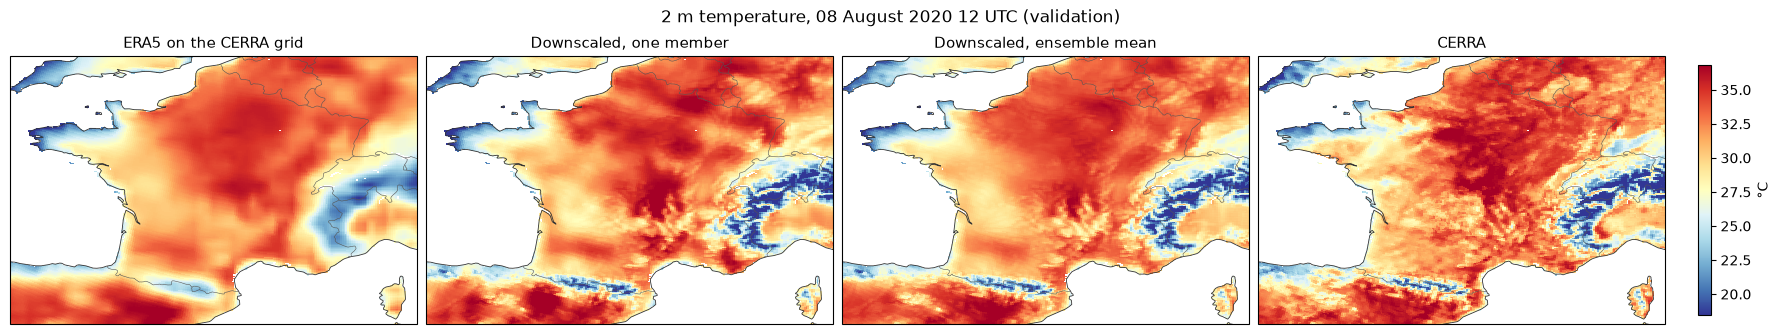

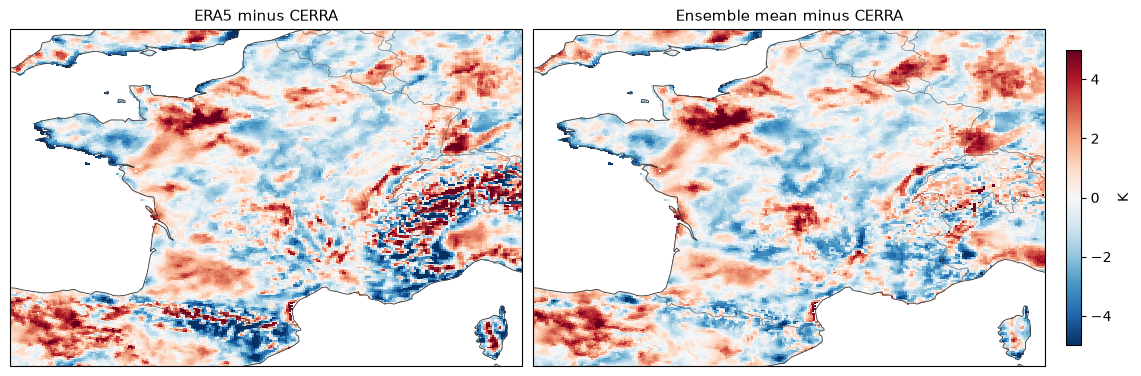

In [9]:
model = dsc.Downscaler.load(OUT / "model.pt", DEVICE)
k = val[int(np.abs(times[val] - pd.Timestamp("2020-08-08 12:00")).argmin())]
ensemble = model.predict(coarse[[k]], times[[k]].to_numpy(), members=CFG.eval_members)[0]   # (member, y, x)
fig = maps([
    ("ERA5 on the CERRA grid", lon, lat, on_land(coarse[k] - ZERO_C)),
    ("Downscaled, one member", lon, lat, on_land(ensemble[0] - ZERO_C)),
    ("Downscaled, ensemble mean", lon, lat, on_land(ensemble.mean(0) - ZERO_C)),
    ("CERRA", lon, lat, on_land(fine[k] - ZERO_C)),
], title=f"2 m temperature, {times[k]:%d %B %Y %H} UTC (validation)", width=4.2)
fig = maps([
    ("ERA5 minus CERRA", lon, lat, on_land(coarse[k] - fine[k])),
    ("Ensemble mean minus CERRA", lon, lat, on_land(ensemble.mean(0) - fine[k])),
], cmap="RdBu_r", vmin=-5, vmax=5, label="K")

Over the whole validation set, by height of the ground: the gain is largest in the mountains, where
ERA5's terrain is furthest from the real one.

In [10]:
edges = elevation_edges([0, 200, 500, 1000, 1500, 2500, 5000])
groups = {"land": land, **{
    f"{int(low)}-{int(high)} m": land & (static["cerra_orography"] >= low) & (static["cerra_orography"] < high)
    for low, high in zip(edges[:-1], edges[1:])}}
groups = {name: mask for name, mask in groups.items() if mask.any()}
model_scores, interpolation = validate(model.net, coarse[val], fine[val], times[val].to_numpy(), model.static_norm,
                                       model.stats, CFG.eval_members, DEVICE, groups=groups)
pd.DataFrame({
    "interpolation RMSE (K)": {g: interpolation[g]["rmse"] for g in groups},
    "model RMSE (K)": {g: model_scores[g]["rmse"] for g in groups},
    "model CRPS (K)": {g: model_scores[g]["crps"] for g in groups},
    "spread / RMSE": {g: model_scores[g]["ssr"] for g in groups},
}).round(3)

,interpolation RMSE (K),model RMSE (K),model CRPS (K),spread / RMSE
land,1.598,1.224,0.614,0.923
0-200 m,1.042,0.991,0.498,0.936
200-500 m,1.304,1.193,0.612,0.894
500-1000 m,1.686,1.334,0.689,0.942
1000-1500 m,2.390,1.488,0.767,0.953
1500-2500 m,3.354,1.890,0.972,0.912
2500-5000 m,5.613,2.460,1.324,0.744


## Using the model, and going further

`runs/tutorial/model.pt` holds the network, the statistics and the static maps, like the published
checkpoint. To downscale a forecast with it, load it in [tutorial.ipynb](tutorial_inference.ipynb) in place of the
published one:

```python
model = Downscaler.load("runs/tutorial/model.pt")
```

To train the full model, use the scripts, which follow the same steps over six years:

```bash
uv run python scripts/download_cerra.py --config config.yaml    # needs a Copernicus account
uv run python scripts/download_cerra.py --config config.yaml --consolidate
uv run python scripts/build_pairs.py --config config.yaml
uv run python scripts/build_pairs.py --config config.yaml --consolidate
uv run python scripts/train_downscaler.py --config config.yaml --out runs/crps
```

Its validation report, `runs/crps/val_report.json`, has the same scores as the table above.